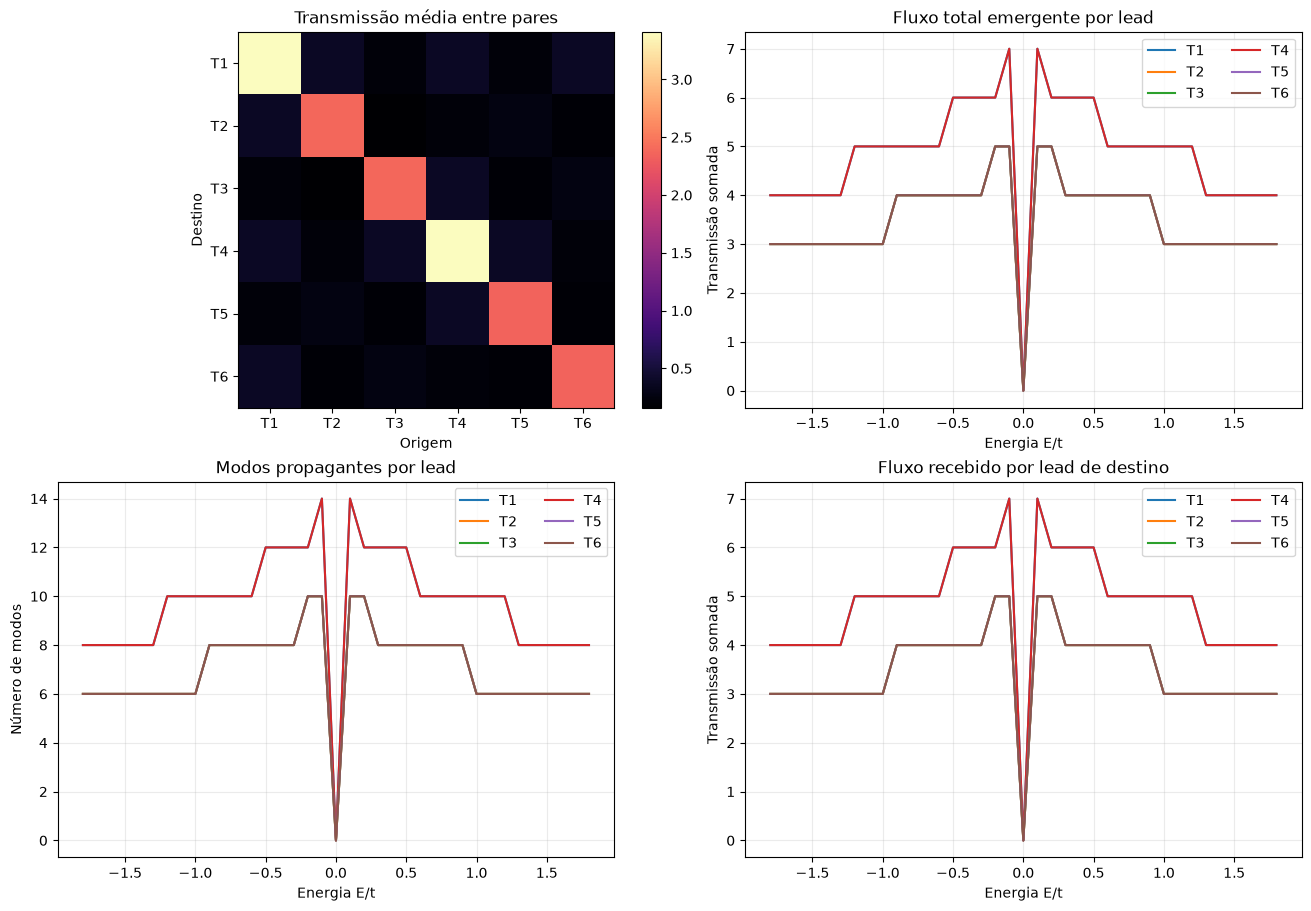

Figura salva em ../figures/lead_observables.png


In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path('../data')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with np.load(DATA_DIR / 'lead_observables.npz') as data:
    energies = data['energies']
    transmissions = data['transmissions']
    mode_counts = data['mode_counts']
    outgoing = data['outgoing']
    incoming = data['incoming']

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

im = axes[0, 0].imshow(np.nanmean(transmissions, axis=0), cmap='magma', origin='upper')
axes[0, 0].set_xticks(range(6), [f'T{i+1}' for i in range(6)])
axes[0, 0].set_yticks(range(6), [f'T{i+1}' for i in range(6)])
axes[0, 0].set_xlabel('Origem')
axes[0, 0].set_ylabel('Destino')
axes[0, 0].set_title('Transmissão média entre pares')
fig.colorbar(im, ax=axes[0, 0], fraction=0.046)

for source in range(6):
    axes[0, 1].plot(energies, outgoing[:, source], label=f'T{source+1}')
axes[0, 1].set_title('Fluxo total emergente por lead')
axes[0, 1].set_xlabel('Energia E/t')
axes[0, 1].set_ylabel('Transmissão somada')
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend(ncol=2)

for lead in range(6):
    axes[1, 0].plot(energies, mode_counts[:, lead], label=f'T{lead+1}')
axes[1, 0].set_title('Modos propagantes por lead')
axes[1, 0].set_xlabel('Energia E/t')
axes[1, 0].set_ylabel('Número de modos')
axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend(ncol=2)

for lead in range(6):
    axes[1, 1].plot(energies, incoming[:, lead], label=f'T{lead+1}')
axes[1, 1].set_title('Fluxo recebido por lead de destino')
axes[1, 1].set_xlabel('Energia E/t')
axes[1, 1].set_ylabel('Transmissão somada')
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend(ncol=2)

output = FIGURES_DIR / 'lead_observables.png'
fig.savefig(output, dpi=220, bbox_inches='tight')
plt.show()
print(f'Figura salva em {output}')

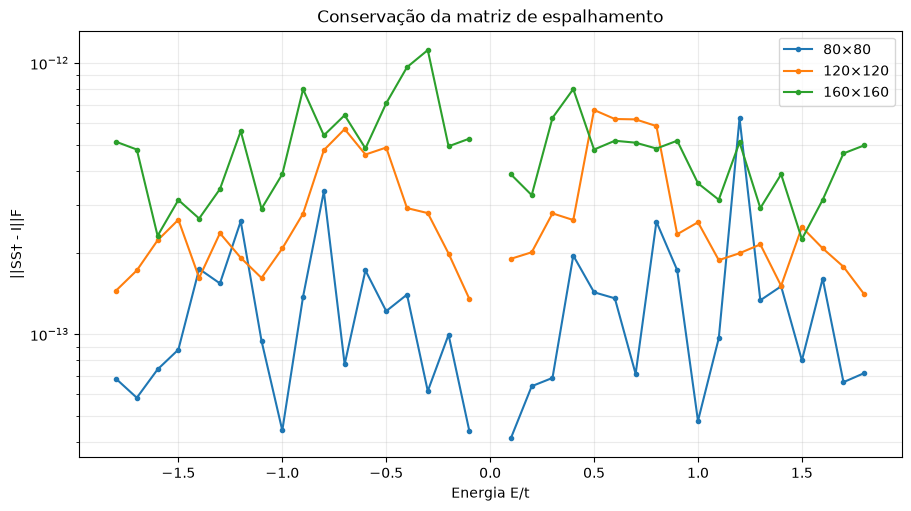

Figura salva em ../figures/convergence_validation.png


In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

DATA_DIR = Path('../data')
FIGURES_DIR = Path('../figures')

with np.load(DATA_DIR / 'convergence_validation.npz') as data:
    energies = data['energies']
    residuals = (data['residual_80'], data['residual_120'], data['residual_160'])

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for size, residual in zip((80, 120, 160), residuals):
    ax.plot(energies, residual, marker='o', markersize=3, label=f'{size}×{size}')
ax.set_yscale('log')
ax.set_xlabel('Energia E/t')
ax.set_ylabel('||SS† - I||F')
ax.set_title('Conservação da matriz de espalhamento')
ax.grid(True, which='both', alpha=0.25)
ax.legend()

output = FIGURES_DIR / 'convergence_validation.png'
fig.savefig(output, dpi=220, bbox_inches='tight')
plt.show()
print(f'Figura salva em {output}')